# Análisis descriptivo de características

Comparar características de HRV y la característica conjunta RR–EDR
entre minutos con y sin apnea, utilizando únicamente desarrollo.

## 1. Preparación y cálculo de características

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path
import os
import sys

# Cambiá esta ruta si guardaste la carpeta en otro lugar
ROOT = Path("/content/drive/MyDrive/TP-PSB-G8-main")

if not (ROOT / "src" / "config.py").exists():
    raise FileNotFoundError(
        "Revisá la ruta: ROOT debe apuntar a la carpeta que contiene "
        "src, notebooks, data y results."
    )

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

print("Proyecto encontrado:", ROOT)

Proyecto encontrado: /content/drive/MyDrive/TP-PSB-G8-main


In [5]:
%pip install -q -r requirements.txt

In [6]:
import pandas as pd

from src.config import SPLIT_CSV, RAW_DIR
from src.data import download_database

split = pd.read_csv(SPLIT_CSV)
registros_dev = split.loc[split["set"] == "dev", "record"].tolist()

print("Registros a descargar:", len(registros_dev))
print("Destino:", RAW_DIR)

faltantes = download_database(
    records=registros_dev,
    raw_dir=RAW_DIR
)

if faltantes:
    print("Archivos que no se pudieron descargar:", faltantes)
else:
    print("Descarga completa.")

Registros a descargar: 47
Destino: /content/drive/MyDrive/TP-PSB-G8-main/data/raw
[1/47] a01
[2/47] a02
[3/47] a03
[4/47] a04
[5/47] a05
[6/47] a08
[7/47] a09
[8/47] a10
[9/47] a12
[10/47] a13
[11/47] a14
[12/47] a15
[13/47] a17
[14/47] a18
[15/47] a19
[16/47] a20
[17/47] b01
[18/47] b02
[19/47] b03
[20/47] c01
[21/47] c02
[22/47] c03
[23/47] c06
[24/47] c07
[25/47] c09
[26/47] c10
[27/47] x03
[28/47] x04
[29/47] x05
[30/47] x07
[31/47] x08
[32/47] x09
[33/47] x10
[34/47] x12
[35/47] x14
[36/47] x16
[37/47] x17
[38/47] x18
[39/47] x19
[40/47] x20
[41/47] x21
[42/47] x23
[43/47] x25
[44/47] x27
[45/47] x28
[46/47] x34
[47/47] x35
Descarga completa.


In [7]:
import time
import pandas as pd

from src.config import RESULTS_DIR
from src.features.build import record_feature_tables
from src.features.variants import BANDS

# Mismas configuraciones del notebook 04
VENTANAS = (180, 240, 300, 360, 420, 512)
ESTIMADORES = ("welch3", "welch7", "multitaper")
METODOS_EDR = ("area", "baseline", "combined")

# Guardamos por registro para poder retomar si Colab se desconecta
CACHE_REGISTROS = RESULTS_DIR / "e3" / "por_registro"
CACHE_REGISTROS.mkdir(parents=True, exist_ok=True)

In [9]:
registro = registros_dev[0]

ruta_acop = CACHE_REGISTROS / f"{registro}_acoplamiento.parquet"
ruta_hrv = CACHE_REGISTROS / f"{registro}_hrv.parquet"

inicio = time.time()

if ruta_acop.exists() and ruta_hrv.exists():
    acop = pd.read_parquet(ruta_acop)
    hrv = pd.read_parquet(ruta_hrv)
    print("Se cargaron los resultados guardados.")
else:
    print(f"Procesando {registro}...", flush=True)

    acop, hrv = record_feature_tables(
        rec=registro,
        widths=VENTANAS,
        estimators=ESTIMADORES,
        edr_methods=METODOS_EDR,
        bands=BANDS
    )

    acop.to_parquet(ruta_acop, index=False)
    hrv.to_parquet(ruta_hrv, index=False)

    print("Resultados calculados y guardados.")

print(f"Tiempo: {(time.time() - inicio) / 60:.1f} minutos")
print("Tabla de acoplamiento:", acop.shape)
print("Tabla de HRV:", hrv.shape)

display(hrv.head())

Procesando a01...
Resultados calculados y guardados.
Tiempo: 0.6 minutos
Tabla de acoplamiento: (26235, 32)
Tabla de HRV: (2915, 15)


,record,minute,apnea,vlf,lf,hf,total,lf_hf,mean_rr,sdnn,rmssd,pnn50,label,corrected,window
0,a01,2,0.001780,0.001248,0.001834,0.000693,0.003818,2.646166,0.797699,0.073631,0.033828,0.138393,0,0.013514,180
1,a01,3,0.001709,0.001245,0.001905,0.000537,0.003752,3.548175,0.783889,0.068020,0.030514,0.100437,0,0.000000,180
2,a01,4,0.001561,0.001311,0.001220,0.000487,0.003145,2.505757,0.789617,0.064016,0.029222,0.110132,0,0.000000,180
3,a01,5,0.000894,0.000704,0.001065,0.000523,0.002378,2.037486,0.813455,0.051961,0.029874,0.081818,0,0.000000,180
4,a01,6,0.001459,0.001309,0.000934,0.000400,0.002691,2.334734,0.786680,0.069217,0.026252,0.057018,0,0.000000,180


In [10]:
inicio_total = time.time()

for numero, registro in enumerate(registros_dev, start=1):
    ruta_acop = CACHE_REGISTROS / f"{registro}_acoplamiento.parquet"
    ruta_hrv = CACHE_REGISTROS / f"{registro}_hrv.parquet"

    if ruta_acop.exists() and ruta_hrv.exists():
        print(
            f"[{numero}/{len(registros_dev)}] {registro}: ya guardado",
            flush=True
        )
        continue

    inicio = time.time()
    print(
        f"[{numero}/{len(registros_dev)}] {registro}: procesando...",
        flush=True
    )

    acop_reg, hrv_reg = record_feature_tables(
        rec=registro,
        widths=VENTANAS,
        estimators=ESTIMADORES,
        edr_methods=METODOS_EDR,
        bands=BANDS
    )

    acop_reg.to_parquet(ruta_acop, index=False)
    hrv_reg.to_parquet(ruta_hrv, index=False)

    print(
        f"  Guardado en {(time.time() - inicio) / 60:.1f} minutos",
        flush=True
    )

print(
    f"\nProceso completo. "
    f"Tiempo de esta corrida: {(time.time() - inicio_total) / 60:.1f} minutos"
)

[1/47] a01: ya guardado
[2/47] a02: procesando...
  Guardado en 0.7 minutos
[3/47] a03: procesando...
  Guardado en 0.7 minutos
[4/47] a04: procesando...
  Guardado en 0.6 minutos
[5/47] a05: procesando...
  Guardado en 0.6 minutos
[6/47] a08: procesando...
  Guardado en 0.7 minutos
[7/47] a09: procesando...
  Guardado en 0.6 minutos
[8/47] a10: procesando...
  Guardado en 0.7 minutos
[9/47] a12: procesando...
  Guardado en 0.7 minutos
[10/47] a13: procesando...
  Guardado en 0.7 minutos
[11/47] a14: procesando...
  Guardado en 0.6 minutos
[12/47] a15: procesando...
  Guardado en 0.7 minutos
[13/47] a17: procesando...
  Guardado en 0.7 minutos
[14/47] a18: procesando...
  Guardado en 0.6 minutos
[15/47] a19: procesando...
  Guardado en 0.7 minutos
[16/47] a20: procesando...
  Guardado en 0.7 minutos
[17/47] b01: procesando...
  Guardado en 0.7 minutos
[18/47] b02: procesando...
  Guardado en 0.7 minutos
[19/47] b03: procesando...
  Guardado en 0.6 minutos
[20/47] c01: procesando...
  G

In [11]:
# Unir los resultados individuales
acoplamiento = pd.concat(
    [
        pd.read_parquet(
            CACHE_REGISTROS / f"{registro}_acoplamiento.parquet"
        )
        for registro in registros_dev
    ],
    ignore_index=True
)

hrv = pd.concat(
    [
        pd.read_parquet(
            CACHE_REGISTROS / f"{registro}_hrv.parquet"
        )
        for registro in registros_dev
    ],
    ignore_index=True
)

# Comprobar que no se repitieron filas de una misma configuración
assert not acoplamiento.duplicated(
    ["record", "minute", "window", "edr", "estimator"]
).any(), "Hay filas duplicadas en acoplamiento."

assert not hrv.duplicated(
    ["record", "minute", "window"]
).any(), "Hay filas duplicadas en HRV."

# Guardar con los nombres que utiliza el notebook 04
CACHE = RESULTS_DIR / "e3"

acoplamiento.to_parquet(
    CACHE / "acoplamiento.parquet", index=False
)
hrv.to_parquet(
    CACHE / "hrv.parquet", index=False
)

print("Registros:", hrv["record"].nunique())
print("Tabla de acoplamiento:", acoplamiento.shape)
print("Tabla de HRV:", hrv.shape)
print("Tablas conjuntas guardadas.")

Registros: 47
Tabla de acoplamiento: (1233495, 32)
Tabla de HRV: (137078, 15)
Tablas conjuntas guardadas.


## 2. Descripción de HRV

In [12]:
# Mantener minutos etiquetados y con hasta 20 % de RR corregidos
hrv_180 = hrv.loc[
    (hrv["window"] == 180)
    & hrv["label"].isin([0, 1])
    & (hrv["corrected"] <= 0.20)
].copy()

caracteristicas = [
    "mean_rr", "sdnn", "rmssd", "pnn50",
    "vlf", "lf", "hf", "lf_hf"
]

resumen = (
    hrv_180
    .groupby("label")[caracteristicas]
    .median()
    .rename(index={0: "Sin apnea", 1: "Con apnea"})
    .T
)

resumen.index.name = "Característica"

print("Cantidad de minutos por grupo:")
print(
    hrv_180["label"]
    .value_counts()
    .rename(index={0: "Sin apnea", 1: "Con apnea"})
)

print("\nMediana de cada característica:")
display(resumen)

Cantidad de minutos por grupo:
label
Sin apnea    13433
Con apnea     8861
Name: count, dtype: int64

Mediana de cada característica:


label,Sin apnea,Con apnea
Característica,,
mean_rr,0.893199,0.890321
sdnn,0.045874,0.071918
rmssd,0.023864,0.025438
pnn50,0.034483,0.045685
vlf,0.000571,0.003042
lf,0.000544,0.000955
hf,0.000242,0.000208
lf_hf,2.268754,4.667054


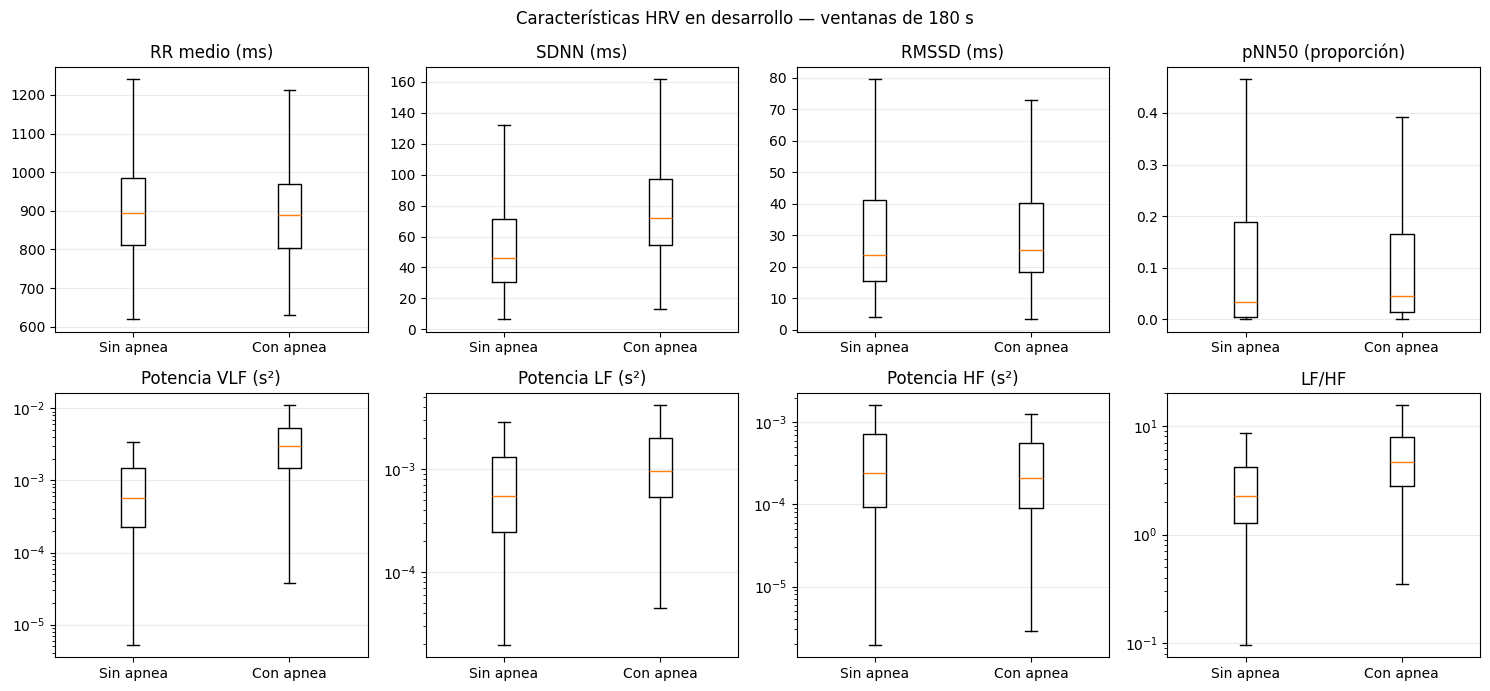

In [13]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(15, 7))

# Mostrar las medidas temporales en milisegundos
factores = {"mean_rr": 1000, "sdnn": 1000, "rmssd": 1000}

titulos = {
    "mean_rr": "RR medio (ms)",
    "sdnn": "SDNN (ms)",
    "rmssd": "RMSSD (ms)",
    "pnn50": "pNN50 (proporción)",
    "vlf": "Potencia VLF (s²)",
    "lf": "Potencia LF (s²)",
    "hf": "Potencia HF (s²)",
    "lf_hf": "LF/HF"
}

for ax, nombre in zip(axes.flat, caracteristicas):
    grupos = []

    for etiqueta in [0, 1]:
        valores = (
            hrv_180.loc[hrv_180["label"] == etiqueta, nombre]
            .to_numpy(dtype=float)
        )
        valores = valores[np.isfinite(valores)]
        valores = valores * factores.get(nombre, 1)

        # La escala logarítmica requiere valores positivos
        if nombre in ["vlf", "lf", "hf", "lf_hf"]:
            valores = valores[valores > 0]

        grupos.append(valores)

    ax.boxplot(grupos, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Sin apnea", "Con apnea"])
    ax.set_title(titulos[nombre])
    ax.grid(axis="y", alpha=0.25)

    if nombre in ["vlf", "lf", "hf", "lf_hf"]:
        ax.set_yscale("log")

plt.suptitle("Características HRV en desarrollo — ventanas de 180 s")
plt.tight_layout()
plt.show()


## 3. Delta de Cliff e intervalos por sujeto

In [14]:
from scipy.stats import rankdata

def delta_cliff(sin_apnea, con_apnea):
    """Delta positivo: valores mayores en el grupo con apnea."""
    normal = np.asarray(sin_apnea, dtype=float)
    apnea = np.asarray(con_apnea, dtype=float)

    normal = normal[np.isfinite(normal)]
    apnea = apnea[np.isfinite(apnea)]

    n_normal, n_apnea = len(normal), len(apnea)

    if n_normal == 0 or n_apnea == 0:
        return np.nan

    # Rangos conjuntos: los empates reciben el rango promedio
    rangos = rankdata(np.concatenate([apnea, normal]))
    u_apnea = (
        rangos[:n_apnea].sum()
        - n_apnea * (n_apnea + 1) / 2
    )

    return 2 * u_apnea / (n_apnea * n_normal) - 1


filas = []

for nombre in caracteristicas:
    normal = hrv_180.loc[hrv_180["label"] == 0, nombre]
    apnea = hrv_180.loc[hrv_180["label"] == 1, nombre]

    delta = delta_cliff(normal, apnea)

    filas.append({
        "Característica": nombre,
        "Delta de Cliff": delta,
        "Magnitud absoluta": abs(delta)
    })

tabla_efectos = (
    pd.DataFrame(filas)
    .sort_values("Magnitud absoluta", ascending=False)
    .reset_index(drop=True)
)

display(tabla_efectos.round(3))

,Característica,Delta de Cliff,Magnitud absoluta
0,vlf,0.616,0.616
1,lf_hf,0.458,0.458
2,sdnn,0.430,0.430
3,lf,0.313,0.313
4,rmssd,0.075,0.075
5,pnn50,0.074,0.074
6,hf,-0.046,0.046
7,mean_rr,-0.038,0.038


In [15]:
from src.config import SPLIT_CSV, SEED

# Asociar cada registro con su sujeto
particion = pd.read_csv(SPLIT_CSV)

datos = hrv_180.merge(
    particion[["record", "subject"]],
    on="record",
    how="left",
    validate="many_to_one"
)

assert datos["subject"].notna().all(), "Hay registros sin sujeto."

sujetos = datos["subject"].unique()

# Guardar los índices de los minutos de cada persona
indices_por_sujeto = [
    np.flatnonzero(datos["subject"].to_numpy() == sujeto)
    for sujeto in sujetos
]

valores = datos[caracteristicas].to_numpy(dtype=float)
etiquetas = datos["label"].to_numpy()

N_BOOT = 2000
rng = np.random.default_rng(SEED)
deltas_boot = np.full((N_BOOT, len(caracteristicas)), np.nan)

print(f"Bootstrap con {len(sujetos)} sujetos.", flush=True)

for b in range(N_BOOT):
    # Sortear sujetos con reposición
    elegidos = rng.integers(0, len(sujetos), size=len(sujetos))

    # Si una persona sale dos veces, sus minutos se incluyen dos veces
    indices = np.concatenate([
        indices_por_sujeto[i] for i in elegidos
    ])

    muestra = valores[indices]
    labels_muestra = etiquetas[indices]

    for j in range(len(caracteristicas)):
        deltas_boot[b, j] = delta_cliff(
            muestra[labels_muestra == 0, j],
            muestra[labels_muestra == 1, j]
        )

    if (b + 1) % 200 == 0:
        print(f"{b + 1}/{N_BOOT}", flush=True)

intervalos = pd.DataFrame({
    "Característica": caracteristicas,
    "IC95 inferior": np.nanpercentile(deltas_boot, 2.5, axis=0),
    "IC95 superior": np.nanpercentile(deltas_boot, 97.5, axis=0),
    "Remuestreos válidos": np.isfinite(deltas_boot).sum(axis=0)
})

tabla_ic = tabla_efectos.merge(
    intervalos,
    on="Característica",
    validate="one_to_one"
)

display(tabla_ic.round(3))

Bootstrap con 19 sujetos.
200/2000
400/2000
600/2000
800/2000
1000/2000
1200/2000
1400/2000
1600/2000
1800/2000
2000/2000


,Característica,Delta de Cliff,Magnitud absoluta,IC95 inferior,IC95 superior,Remuestreos válidos
0,vlf,0.616,0.616,0.400,0.783,2000
1,lf_hf,0.458,0.458,0.273,0.654,2000
2,sdnn,0.430,0.430,0.163,0.659,2000
3,lf,0.313,0.313,0.021,0.589,2000
4,rmssd,0.075,0.075,-0.257,0.399,2000
5,pnn50,0.074,0.074,-0.268,0.401,2000
6,hf,-0.046,0.046,-0.389,0.284,2000
7,mean_rr,-0.038,0.038,-0.362,0.281,2000


### Comparación de características de HRV entre minutos con y sin apnea

Se analizaron ocho características de HRV calculadas en ventanas de 180 segundos, utilizando únicamente los registros de desarrollo. Se incluyeron minutos con etiqueta válida y con hasta un 20 % de intervalos RR corregidos.

Para medir la separación entre los grupos se utilizó **delta de Cliff**. Un valor positivo indica que la característica tiende a ser mayor durante la apnea; uno negativo indica que tiende a ser menor. Los valores cercanos a cero indican poca separación según esta medida.

Los **intervalos de confianza del 95 %** se calcularon mediante 2000 remuestreos de los 19 sujetos. Se conservaron juntos todos los minutos de cada persona para tener en cuenta que sus observaciones están relacionadas.

### Resultados

- **VLF** presentó la mayor separación estimada: delta de 0,616 e intervalo de 0,400 a 0,783.
- **LF/HF y SDNN** también tendieron a ser mayores durante la apnea, con intervalos por encima de cero.
- **LF** mostró una tendencia positiva, aunque su límite inferior quedó cerca de cero.
- **RMSSD, pNN50, HF y RR medio** presentaron intervalos que incluyeron cero. No se pudo establecer una dirección clara del efecto con estos datos; esto no demuestra que los grupos sean iguales.

Estos resultados son **exploratorios**. Los intervalos no están ajustados por comparaciones múltiples y no permiten afirmar, por sí solos, que una característica sea estadísticamente mejor que otra.

## 4. Comparación dentro de cada sujeto

In [16]:
from scipy.stats import wilcoxon
from src.features.variants import FORMS, HRV_FEATURES
from src.stats.tests import holm

# F elegida por el grupo: área del QRS, 240 s, Welch de 3 segmentos
f_tab = acoplamiento.loc[
    (acoplamiento["edr"] == "area")
    & (acoplamiento["window"] == 240)
    & (acoplamiento["estimator"] == "welch3")
].copy()

# Reutilizar la fórmula del proyecto
f_tab["F"] = FORMS["potencia sola"](f_tab, "ap_l", "v2_r")

# Comparar F y HRV sobre los mismos minutos válidos
f_tab = f_tab.loc[
    f_tab["label"].isin([0, 1])
    & (f_tab["corrected"] <= 0.20),
    ["record", "minute", "F"]
]

comparacion = hrv_180.merge(
    f_tab,
    on=["record", "minute"],
    validate="one_to_one"
).merge(
    particion[["record", "subject"]],
    on="record",
    validate="many_to_one"
)

# Incluir las diez características HRV previstas y F
features_comparadas = HRV_FEATURES + ["F"]

comparacion = comparacion.loc[
    np.isfinite(comparacion[features_comparadas]).all(axis=1)
].copy()

# Un efecto por persona y característica.
# Solo participan personas con minutos de ambas clases.
efectos_sujeto = []

for sujeto, grupo in comparacion.groupby("subject"):
    if grupo["label"].nunique() != 2:
        continue

    fila = {"subject": sujeto}

    for nombre in features_comparadas:
        fila[nombre] = delta_cliff(
            grupo.loc[grupo["label"] == 0, nombre],
            grupo.loc[grupo["label"] == 1, nombre]
        )

    efectos_sujeto.append(fila)

efectos_sujeto = pd.DataFrame(efectos_sujeto)

if len(efectos_sujeto) < 2:
    raise ValueError("No hay suficientes sujetos con ambas clases.")

# Wilcoxon bilateral: ¿los efectos por sujeto se centran en cero?
resultados = []

for nombre in features_comparadas:
    efectos = efectos_sujeto[nombre].to_numpy()

    p = (
        1.0 if np.all(efectos == 0)
        else wilcoxon(efectos, alternative="two-sided").pvalue
    )

    resultados.append({
        "Característica": nombre,
        "Sujetos": len(efectos),
        "Delta mediana por sujeto": np.median(efectos),
        "p Wilcoxon": p
    })

tabla_tests = pd.DataFrame(resultados)

# Ajustar las once comparaciones como una misma familia
tabla_tests["p Holm"] = holm(tabla_tests["p Wilcoxon"])
tabla_tests["p Holm < 0.05"] = tabla_tests["p Holm"] < 0.05

print("Minutos comunes válidos:", len(comparacion))
print("Sujetos con ambas clases:", len(efectos_sujeto))
display(tabla_tests.round(4))

Minutos comunes válidos: 22275
Sujetos con ambas clases: 18


,Característica,Sujetos,Delta mediana por sujeto,p Wilcoxon,p Holm,p Holm < 0.05
0,mean_rr,18,0.2569,0.0665,0.0665,False
1,sdnn,18,0.7003,0.0000,0.0001,True
2,rmssd,18,0.5452,0.0002,0.0006,True
3,pnn50,18,0.4854,0.0001,0.0004,True
4,apnea,18,0.7533,0.0000,0.0001,True
5,vlf,18,0.7362,0.0000,0.0001,True
6,lf,18,0.6984,0.0000,0.0001,True
7,hf,18,0.3817,0.0040,0.0080,True
8,total,18,0.7221,0.0000,0.0001,True
9,lf_hf,18,0.3724,0.0000,0.0001,True


### Comparación dentro de cada sujeto

Para evaluar si las características cambian durante la apnea dentro de una misma persona, se calculó delta de Cliff por sujeto. Se utilizaron los mismos minutos válidos para todas las características: HRV con ventanas de 180 s y F con ventanas de 240 s.

Participaron 18 sujetos con minutos válidos de ambas clases. Un delta positivo indica valores generalmente mayores durante la apnea.

Como análisis exploratorio adicional, se aplicó Wilcoxon bilateral sobre los efectos por sujeto, tomando a cada persona como unidad independiente. Esta prueba no exige normalidad, aunque supone una distribución aproximadamente simétrica de los efectos alrededor de su centro. Se corrigieron las once comparaciones mediante Holm.

Todas las características excepto RR medio presentaron p ajustado menor que 0,05. F mostró una mediana de delta por sujeto de 0,7282, indicando una tendencia a valores mayores durante la apnea.

Estos resultados describen cambios dentro de las personas. No demuestran que F sea mejor que VLF ni establecen todavía un punto de corte para detectar apnea. Los valores p mostrados como 0,0000 se deben al redondeo.

## 5. Descripción de F y VLF

In [17]:
# Resumir ambas características sobre los mismos minutos válidos.
filas = []

for nombre in ["F", "vlf"]:
    normal = comparacion.loc[comparacion["label"] == 0, nombre]
    apnea = comparacion.loc[comparacion["label"] == 1, nombre]

    filas.append({
        "Característica": nombre,
        "Mediana sin apnea": normal.median(),
        "Q25 sin apnea": normal.quantile(0.25),
        "Q75 sin apnea": normal.quantile(0.75),
        "Mediana con apnea": apnea.median(),
        "Q25 con apnea": apnea.quantile(0.25),
        "Q75 con apnea": apnea.quantile(0.75),
        "Delta agrupado": delta_cliff(normal, apnea)
    })

resumen_f_vlf = pd.DataFrame(filas)
display(resumen_f_vlf.round(6))

,Característica,Mediana sin apnea,Q25 sin apnea,Q75 sin apnea,Mediana con apnea,Q25 con apnea,Q75 con apnea,Delta agrupado
0,F,-7.903263,-8.934243,-6.927111,-5.802426,-6.576432,-5.153049,0.746552
1,vlf,0.000570,0.000224,0.001480,0.003042,0.001479,0.005401,0.616266


### Descripción de F y VLF sobre minutos comunes

F y VLF se compararon sobre los mismos 22.275 minutos válidos de desarrollo.

La mediana de F pasó de −7,903 sin apnea a −5,802 con apnea. Su delta de Cliff agrupado fue 0,747, frente a 0,616 de VLF. Ambas características tendieron a presentar valores mayores durante la apnea.

F mostró una mayor separación descriptiva entre clases. Este resultado no demuestra una ventaja estadísticamente significativa sobre VLF. Además, ambas características fueron elegidas utilizando desarrollo, por lo que su desempeño en estos datos puede ser optimista.